Importing the Libraries After Cleaning & Remodelling The Data To Match Star Schema.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

Importing the Data


In [3]:
purchase_behaviour = pd.read_excel(r'c:\Users\farou\Downloads\df\QVI_purchase_behaviour.xlsx')
transactions = pd.read_excel(r'c:\Users\farou\Downloads\df\QVI_transaction_data.xlsx', sheet_name='in')
dim_product = pd.read_excel(r'c:\Users\farou\Downloads\df\dim_product.xlsx')




In [4]:
dim_product

,PROD_NBR,PROD_NAME,Brand_Name,Pack_Weight
0,1,SMITHSs Crinkle Cut Chips Barbecue 170g,Smiths,170g
1,2,Cobs Popd Sour Crm &Chives Chips 110g,Cobs,110g
2,3,Kettle Sensations Camembert & Fig 150g,Kettle,150g
3,4,DORITOS Corn Chp Supreme 380g,Doritos,380g
4,5,Natural Chip Compny SeaSalt175g,Natural Chip Co,175g
...,...,...,...,...
102,110,WOOLWORTHS Original Corn Chips 200g,Woolworths,200g
103,111,SMITHSs Chip Thinly Cut Original 175g,Smiths,175g
104,112,Tyrrells Crisps Ched & Chives 165g,Tyrrells,165g
105,113,Twisties Chicken270g,Twisties,270g


In [5]:
dim_product.head()

,PROD_NBR,PROD_NAME,Brand_Name,Pack_Weight
0,1,SMITHSs Crinkle Cut Chips Barbecue 170g,Smiths,170g
1,2,Cobs Popd Sour Crm &Chives Chips 110g,Cobs,110g
2,3,Kettle Sensations Camembert & Fig 150g,Kettle,150g
3,4,DORITOS Corn Chp Supreme 380g,Doritos,380g
4,5,Natural Chip Compny SeaSalt175g,Natural Chip Co,175g


Formatting & Merging the Data

In [6]:
## Merging the dataframes
Total_schema = purchase_behaviour.merge( transactions, on='LYLTY_CARD_NBR').merge(dim_product , on='PROD_NBR')
Total_schema
column_order = ['TXN_ID', 'LYLTY_CARD_NBR', 'PROD_NBR', 'PROD_NAME', 'PROD_QTY' , 'Brand_Name', 'Pack_Weight', 'TOT_Price', 'DATE', 'STORE_NBR', 'PREMIUM_CUSTOMER', 'LIFESTAGE']
Total_schema = Total_schema[column_order]
Total_schema

,TXN_ID,LYLTY_CARD_NBR,PROD_NBR,PROD_NAME,PROD_QTY,Brand_Name,Pack_Weight,TOT_Price,DATE,STORE_NBR,PREMIUM_CUSTOMER,LIFESTAGE
0,1,1000,5,Natural Chip Compny SeaSalt175g,2,Natural Chip Co,175g,6.0,2018-10-17,1,Premium,YOUNG SINGLES/COUPLES
1,2,1002,58,RRD Rock Deli Chikn&Garlic Aioli 150g,1,RRD,150g,2.7,2018-09-16,1,Mainstream,YOUNG SINGLES/COUPLES
2,3,1003,52,GRNWVES Waves Sour Cream&Chives 210G,1,Grain Waves,210g,3.6,2019-03-07,1,Budget,YOUNG FAMILIES
3,4,1003,106,Natural ChipCo Hony Soy Chckn175g,1,Natural Chip Co,175g,3.0,2019-03-08,1,Budget,YOUNG FAMILIES
4,5,1004,96,WOOLWORTHS Original Stacked Chips 160g,1,Woolworths,160g,1.9,2018-11-02,1,Mainstream,OLDER SINGLES/COUPLES
...,...,...,...,...,...,...,...,...,...,...,...,...
249663,240350,2370651,4,DORITOS Corn Chp Supreme 380g,2,Doritos,380g,13.0,2018-08-03,88,Mainstream,MIDAGE SINGLES/COUPLES
249664,240378,2370701,24,GRNWVES Waves Sweet Chilli 210g,2,Grain Waves,210g,7.2,2018-12-08,88,Mainstream,YOUNG FAMILIES
249665,240394,2370751,60,Kettle Tortilla ChpsFeta&Garlic 150g,2,Kettle,150g,9.2,2018-10-01,88,Premium,YOUNG FAMILIES
249666,240480,2370961,70,Tyrrells Crisps Lightly Salted 165g,2,Tyrrells,165g,8.4,2018-10-24,88,Budget,OLDER FAMILIES


Data Profiling & EDA

In [7]:

import sys, subprocess, importlib

if importlib.util.find_spec('sweetviz') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'sweetviz'])

sv = importlib.import_module('sweetviz')
report = sv.analyze(Total_schema)
report.show_html('report.html')

                                             |          | [  0%]   00:00 -> (? left)

Report report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


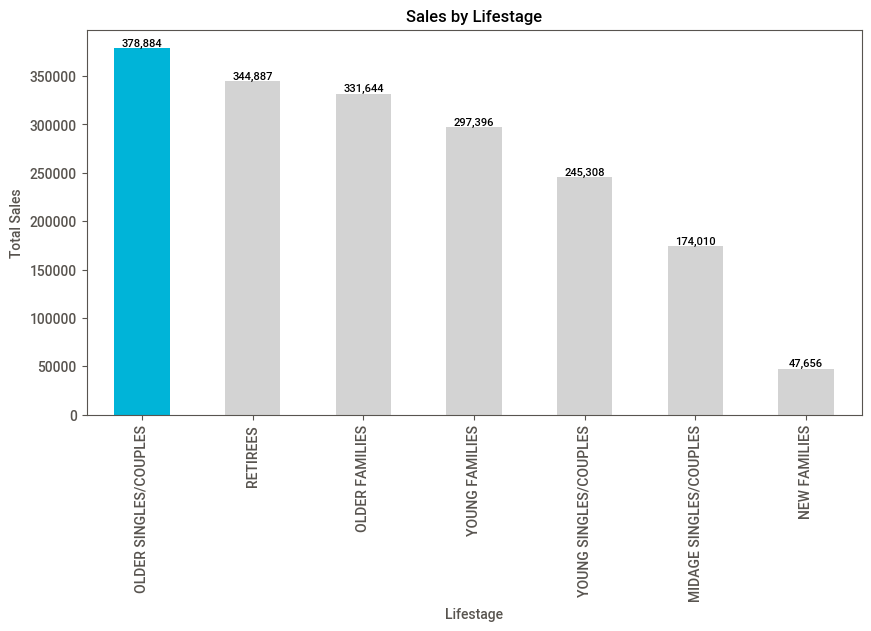

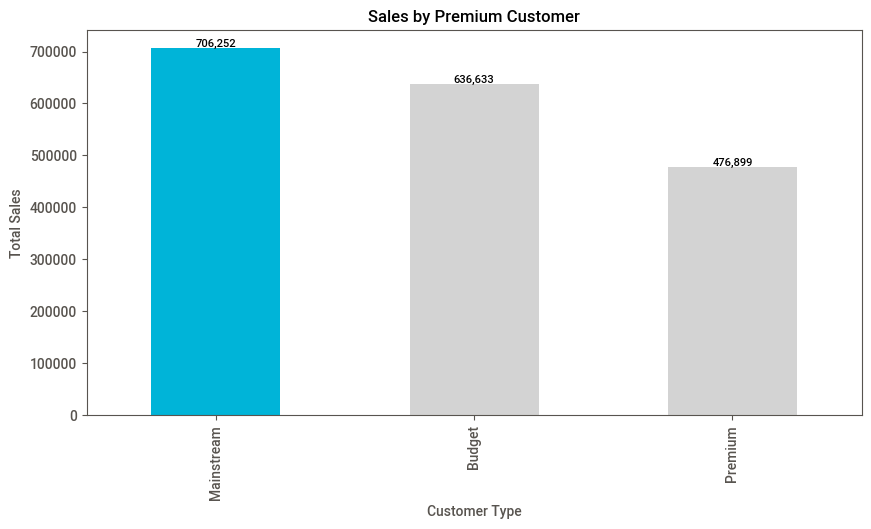

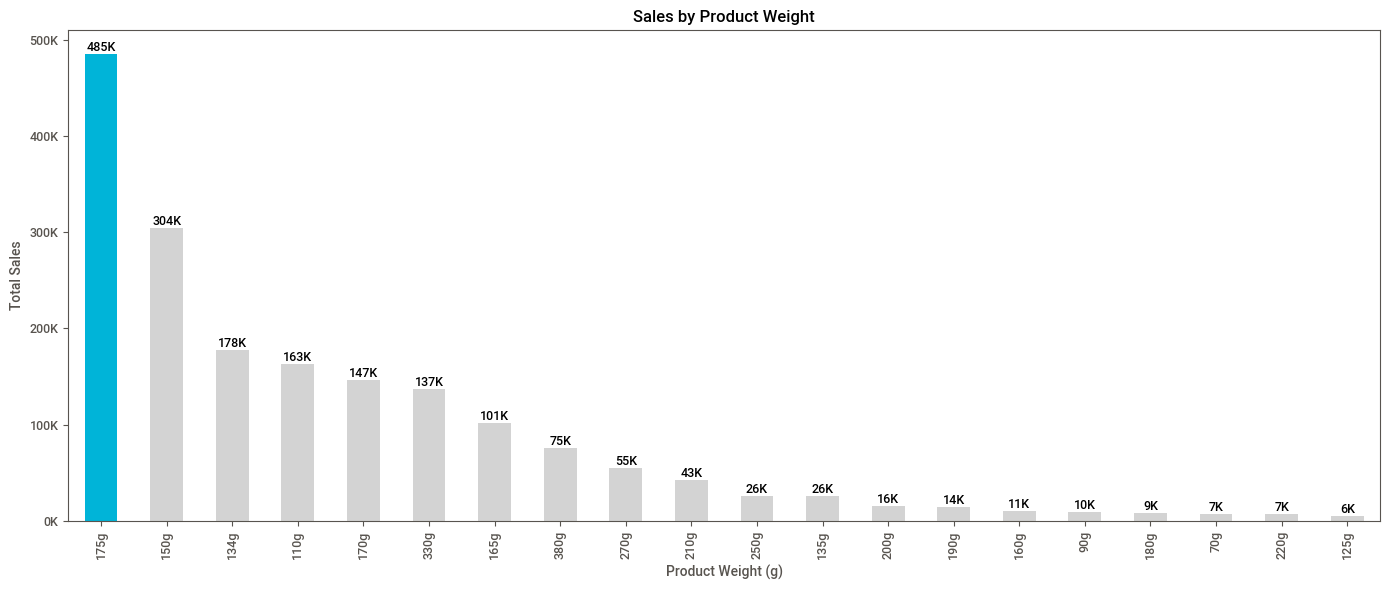

In [8]:
# Let's determine the sales by different segments
# 1- By Lifestage
sales_by_lifestage = Total_schema.groupby('LIFESTAGE')['TOT_Price'].sum().sort_values(ascending=False)

colors = ['#00b4d8' if i == 0 else '#d3d3d3' for i in range(len(sales_by_lifestage))]

ax = sales_by_lifestage.plot(kind='bar', figsize=(10, 5), title='Sales by Lifestage', color=colors)


for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=8)

plt.ylabel('Total Sales', fontsize=10)
plt.xlabel('Lifestage', fontsize=10)
ax.tick_params(axis='both', labelsize=10)
plt.show()

#2- By Premium Customer
sales_by_premium = Total_schema.groupby('PREMIUM_CUSTOMER')['TOT_Price'].sum().sort_values(ascending=False)
colors = ['#00b4d8' if i == 0 else '#d3d3d3' for i in range(len(sales_by_premium))]
ax = sales_by_premium.plot(kind='bar', figsize=(10, 5), title='Sales by Premium Customer', color=colors)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=8)
plt.ylabel('Total Sales', fontsize=10)
plt.xlabel('Customer Type', fontsize=10)
ax.tick_params(axis='both', labelsize=10)
plt.show()

# 3- Sales By Product Weight
sales_by_weight = Total_schema.groupby('Pack_Weight')['TOT_Price'].sum().sort_values(ascending=False)
colors = ['#00b4d8' if i == 0 else '#d3d3d3' for i in range(len(sales_by_weight))]

ax = sales_by_weight.plot(kind='bar', figsize=(14, 6), title='Sales by Product Weight', color=colors)

for p in ax.patches:
    ax.annotate(f'{p.get_height()/1000:.0f}K',       
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)  

plt.ylabel('Total Sales', fontsize=10)
plt.xlabel('Product Weight (g)', fontsize=10)
ax.tick_params(axis='both', labelsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}K')) 
plt.tight_layout()
plt.show()

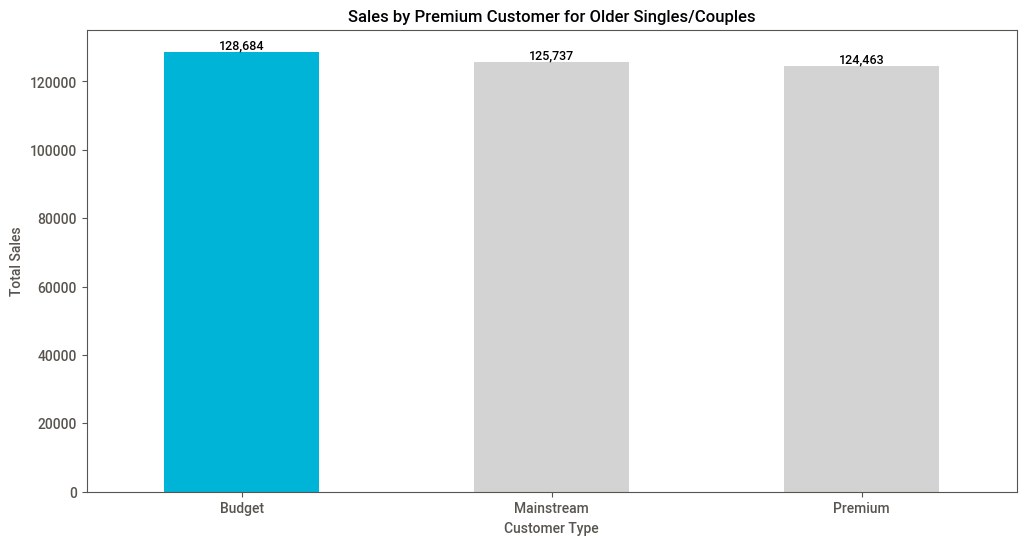

In [9]:
# Comparing Older signles/Couples sales for every PREIMUM CUSTOMER

total_sales_by_lifestage_oldersi = Total_schema[Total_schema['LIFESTAGE'] == 'OLDER SINGLES/COUPLES'].groupby('PREMIUM_CUSTOMER')['TOT_Price'].sum().sort_values(ascending=False)
colors = ['#00b4d8' if i == 0 else '#d3d3d3' for i in range(len(total_sales_by_lifestage_oldersi))]
ax =  total_sales_by_lifestage_oldersi.plot(kind='bar', figsize=(12, 6), title='Sales by Premium Customer for Older Singles/Couples', color=colors)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.xlabel('Customer Type', fontsize=10)
plt.ylabel('Total Sales', fontsize=10)
plt.xticks(rotation=0)
ax.tick_params(axis='both', labelsize=10)
plt.show()

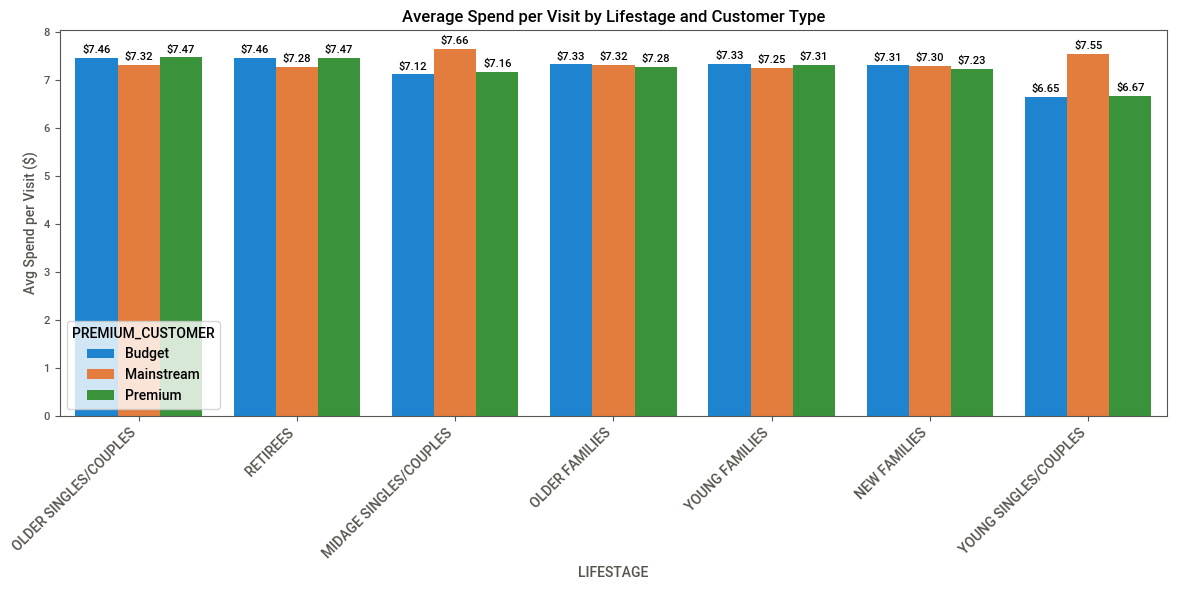

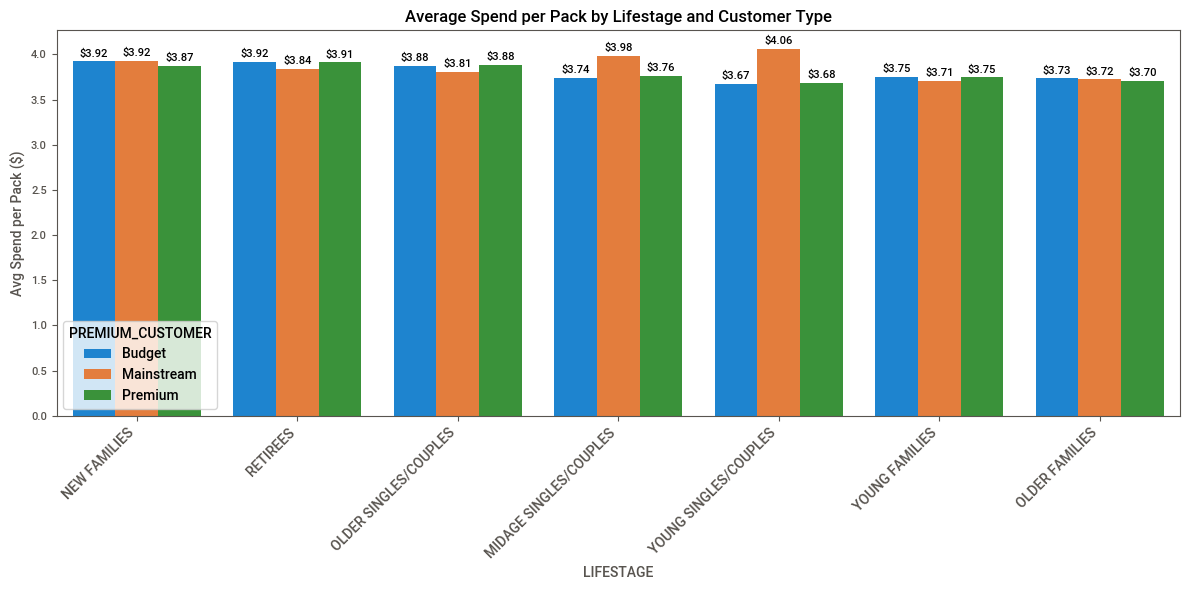

In [10]:
# Step 1: groupby with two aggregations at once
avg_spend = (
    Total_schema.groupby(['LIFESTAGE', 'PREMIUM_CUSTOMER'])
    .agg(
        total_revenue=('TOT_Price', 'sum'),      # what aggregation gives total $?
        total_visits=('TXN_ID', 'nunique')            # what aggregation gives unique visit count?
    )
    .reset_index()
)

# Step 2: compute the rate
avg_spend['avg_spend_per_visit'] = avg_spend['total_revenue'] / avg_spend['total_visits']

# Step 3 (optional but recommended): sort lifestages by overall avg for readability
order = (
    avg_spend.groupby('LIFESTAGE')['avg_spend_per_visit']
    .mean()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=avg_spend,
    x='LIFESTAGE',
    y='avg_spend_per_visit',
    hue='PREMIUM_CUSTOMER',
    order=order
)


for container in ax.containers:
    ax.bar_label(container, fmt='$%.2f', fontsize=8, padding=2)

plt.xticks(rotation=45, ha='right' , fontsize=10)
plt.ylabel('Avg Spend per Visit ($)')
plt.title('Average Spend per Visit by Lifestage and Customer Type')
plt.tight_layout()
plt.show()


# Step 1: groupby with two aggregations at once
avg_spend = (
    Total_schema.groupby(['LIFESTAGE', 'PREMIUM_CUSTOMER'])
    .agg(
        total_revenue=('TOT_Price', 'sum'),     
        total_quantity=('PROD_QTY', 'sum')          
    )
    .reset_index()
)

# Step 2: compute the rate
avg_spend['avg_spend_per_pack'] = avg_spend['total_revenue'] / avg_spend['total_quantity']

# Step 3 (optional but recommended): sort lifestages by overall avg for readability
order = (
    avg_spend.groupby('LIFESTAGE')['avg_spend_per_pack']
    .mean()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=avg_spend,
    x='LIFESTAGE',
    y='avg_spend_per_pack',
    hue='PREMIUM_CUSTOMER',
    order=order
)


for container in ax.containers:
    ax.bar_label(container, fmt='$%.2f', fontsize=8, padding=2)

plt.xticks(rotation=45, ha='right' , fontsize=10)
plt.ylabel('Avg Spend per Pack ($)')
plt.title('Average Spend per Pack by Lifestage and Customer Type')
plt.tight_layout()
plt.show()

T-test

In [ ]:

price_per_unit_data = (
    Total_schema.loc[
        Total_schema['LIFESTAGE'].isin(['YOUNG SINGLES/COUPLES', 'MIDAGE SINGLES/COUPLES']),
        ['PREMIUM_CUSTOMER', 'TOT_Price', 'PROD_QTY']
    ].copy()
)

price_per_unit_data = price_per_unit_data[price_per_unit_data['PROD_QTY'] > 0]
price_per_unit_data['price_per_unit'] = price_per_unit_data['TOT_Price'] / price_per_unit_data['PROD_QTY']

mainstream = price_per_unit_data.loc[
    price_per_unit_data['PREMIUM_CUSTOMER'] == 'Mainstream',
    'price_per_unit'
]

non_mainstream = price_per_unit_data.loc[
    price_per_unit_data['PREMIUM_CUSTOMER'] != 'Mainstream',
    'price_per_unit'
]

result = stats.ttest_ind(mainstream, non_mainstream, alternative='greater')
print(f"p-value: {result.pvalue:.2e}")

p-value: 0.00e+00


In [12]:
customer_count = purchase_behaviour.groupby(['LIFESTAGE', 'PREMIUM_CUSTOMER'])['LYLTY_CARD_NBR'].nunique().unstack()
customer_count['Grand Total'] = customer_count.sum(axis=1)
customer_count.loc['Grand Total'] = customer_count.sum()
customer_count

PREMIUM_CUSTOMER,Budget,Mainstream,Premium,Grand Total
LIFESTAGE,,,,
MIDAGE SINGLES/COUPLES,1504,3340,2431,7275
NEW FAMILIES,1112,849,588,2549
OLDER FAMILIES,4675,2831,2274,9780
OLDER SINGLES/COUPLES,4929,4930,4750,14609
RETIREES,4454,6479,3872,14805
YOUNG FAMILIES,4017,2728,2433,9178
YOUNG SINGLES/COUPLES,3779,8088,2574,14441
Grand Total,24470,29245,18922,72637


C:\Users\farou\AppData\Local\Temp\ipykernel_9020\746405364.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


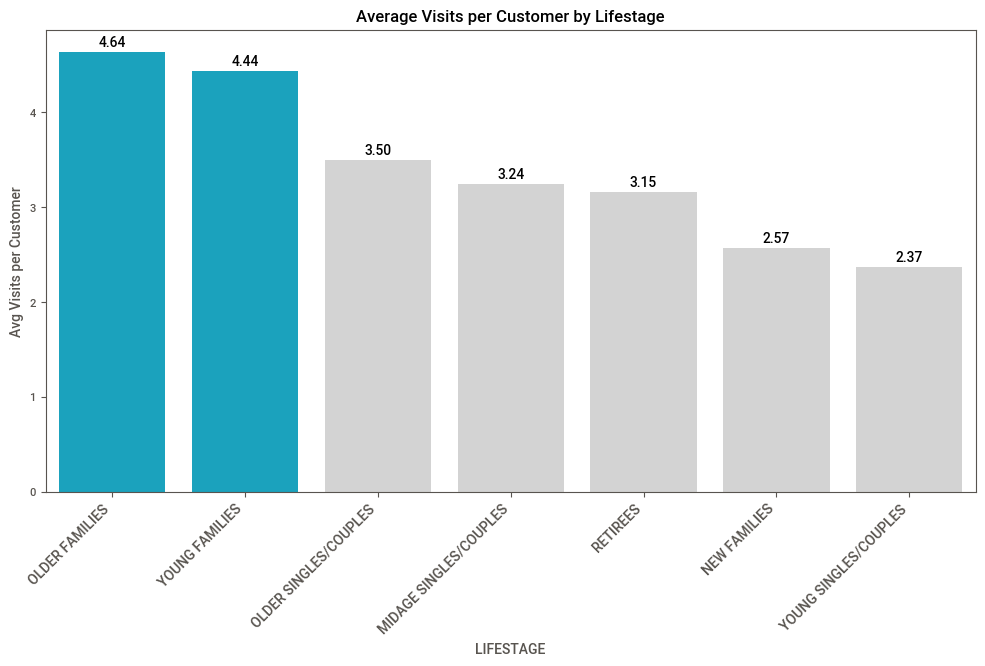

In [13]:
# Step 2: get total customers per lifestage from your earlier customer_count table
# drop BOTH the Grand Total row and the Grand Total column before summing
customers_by_lifestage = (
    customer_count
    .drop('Grand Total', axis=0, errors='ignore')
    .drop('Grand Total', axis=1, errors='ignore')
    .sum(axis=1)
)
customers_by_lifestage = customers_by_lifestage.reset_index()
customers_by_lifestage.columns = ['LIFESTAGE', 'total_customers']

# Step 3: merge the two on LIFESTAGE
visits_by_lifestage = Total_schema.groupby('LIFESTAGE')['TXN_ID'].nunique().reset_index()
visits_by_lifestage.columns = ['LIFESTAGE', 'total_visits']

visits_per_customer = visits_by_lifestage.merge(customers_by_lifestage, on='LIFESTAGE')

# Step 4: compute the ratio
visits_per_customer['avg_visits_per_customer'] = (
    visits_per_customer['total_visits'] / visits_per_customer['total_customers']
)

visits_per_customer.sort_values('avg_visits_per_customer', ascending=False)
colors = ['#00b4d8' if i in (0, 1) else '#d3d3d3' for i in range(len(visits_per_customer))]
order = (
    visits_per_customer
    .sort_values('avg_visits_per_customer', ascending=False)
    .LIFESTAGE
    .tolist()
)
# increase the font size of the x axis labels and rotate them for better readability

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=visits_per_customer,
    x='LIFESTAGE',
    y='avg_visits_per_customer',
    order=order,
    palette=colors
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=10, padding=2
)
plt.xticks(rotation=45, ha='right' , fontsize=10)
plt.ylabel('Avg Visits per Customer')
plt.title('Average Visits per Customer by Lifestage')
plt.show()

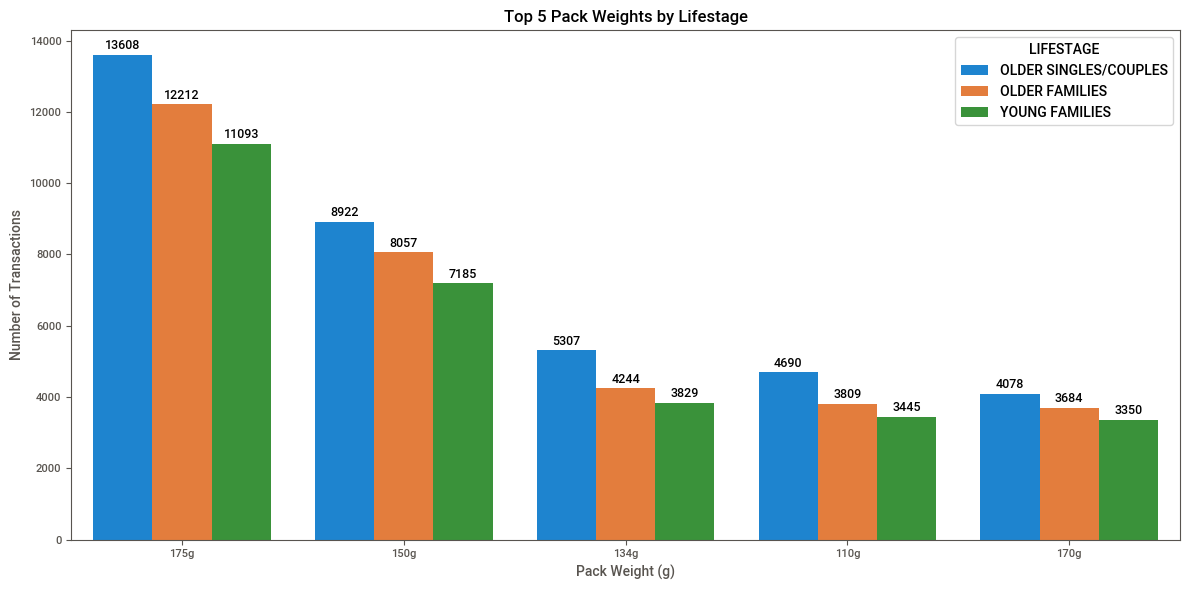

In [14]:
# Analyzing What Size older familes, young families, and older singles/couples buy the most
total_sales_by_lifestage_weightold = Total_schema[Total_schema['LIFESTAGE'].isin(['OLDER FAMILIES', 'YOUNG FAMILIES', 'OLDER SINGLES/COUPLES'])].groupby(['LIFESTAGE', 'Pack_Weight'])['TXN_ID'].count().reset_index()
total_sales_by_lifestage_weightold
# Plot It
top5_per_lifestage = (
    total_sales_by_lifestage_weightold
    .sort_values('TXN_ID', ascending=False)
    .groupby('LIFESTAGE')
    .head(5)
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=top5_per_lifestage,
    x='Pack_Weight',
    y='TXN_ID',
    hue='LIFESTAGE'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=9, padding=2)
plt.xlabel('Pack Weight (g)')
plt.ylabel('Number of Transactions')
plt.title('Top 5 Pack Weights by Lifestage')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Profitability vs. Foot Traffic: While Older Singles/Couples drive our highest revenue and represent our most profitable segment, Older and Younger Families frequent our stores the most. Because the Average Order Value (AOV) remains stable across all demographics, our growth strategy should focus on targeting these high-frequency families to increase their spend per visit.

Product Preferences: Our overall best-selling chips are the 175g and 150g sizes.

Digital Expansion for Retirees: Retirees constitute our largest audience, but mobility challenges limit their shopping frequency. To fully capitalize on this massive customer base, we should launch a mobile app or e-commerce website, allowing them to conveniently have their favorite chips delivered straight to their doorstep.

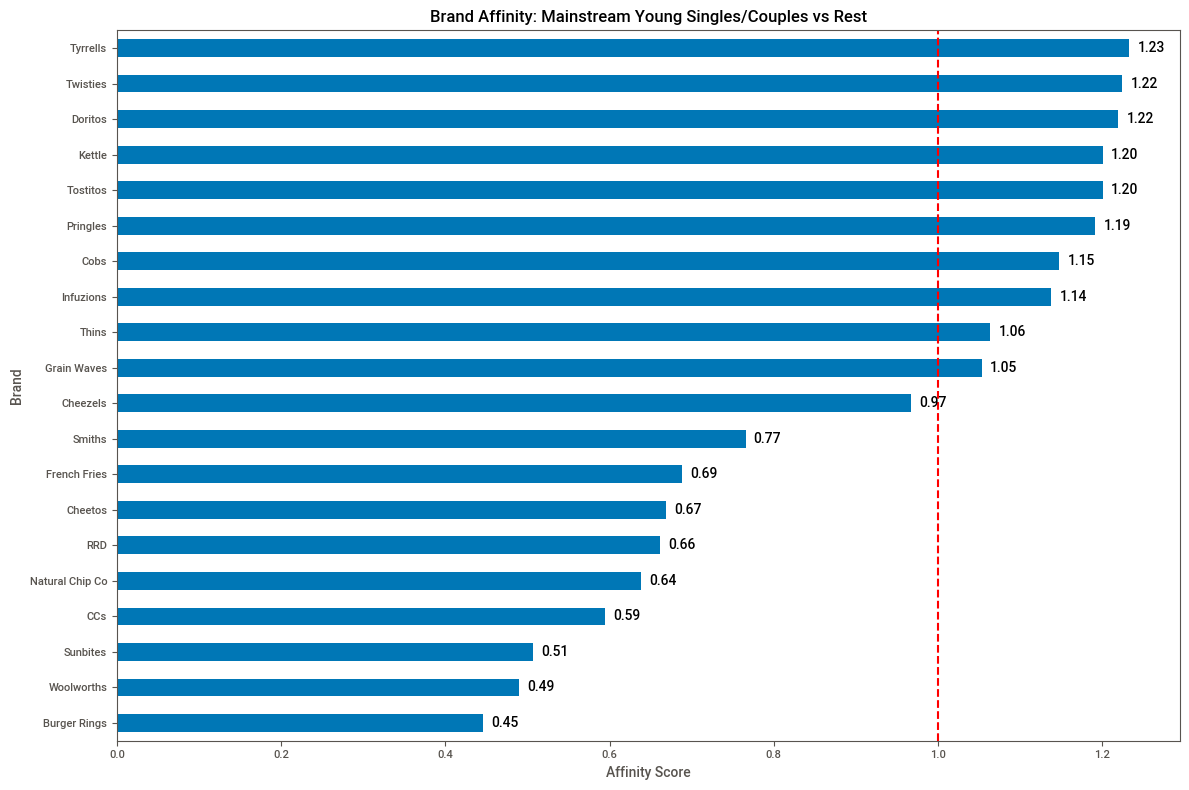

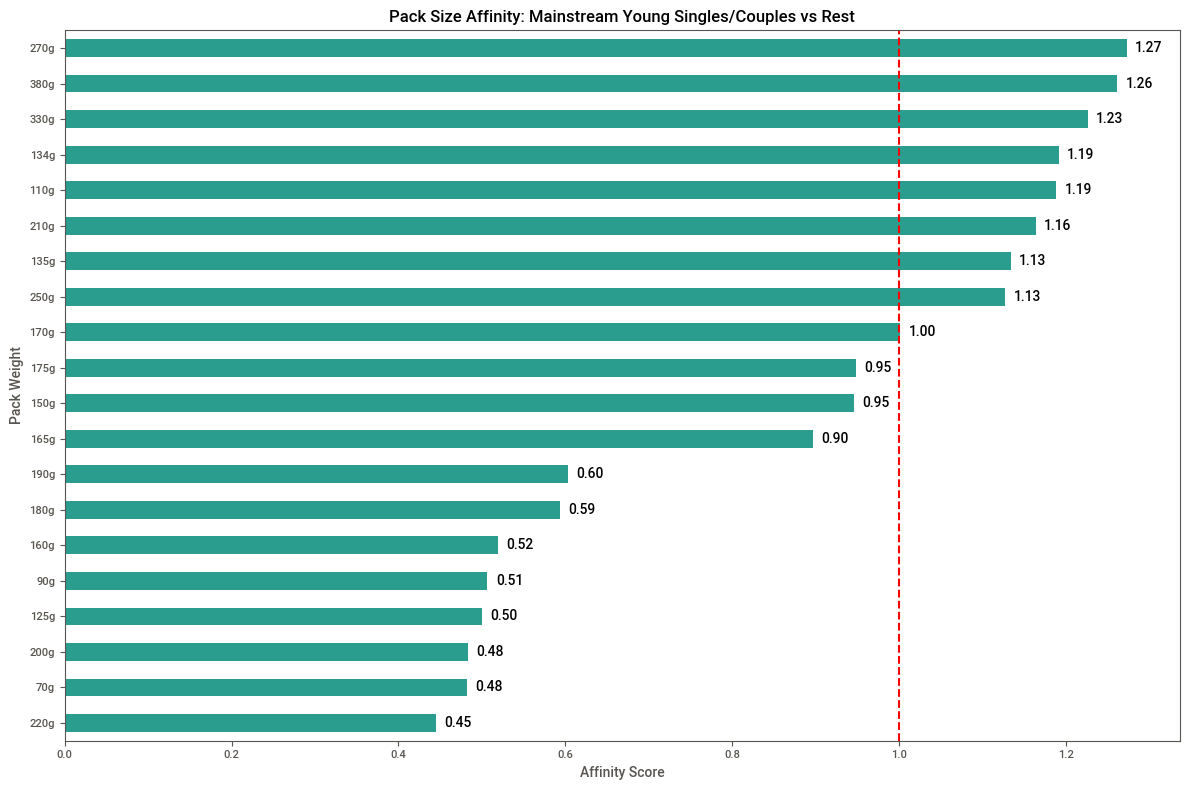

In [ ]:

# Use existing Total_schema if total_schema is not defined
if 'total_schema' not in globals() and 'Total_schema' in globals():
    total_schema = Total_schema

segment = total_schema[
    (total_schema['LIFESTAGE'] == 'YOUNG SINGLES/COUPLES') &
    (total_schema['PREMIUM_CUSTOMER'] == 'Mainstream')
].copy()
others = total_schema.drop(segment.index).copy()

# Brand affinity
brand_qty_segment = segment.groupby('Brand_Name')['PROD_QTY'].sum()
brand_qty_others = others.groupby('Brand_Name')['PROD_QTY'].sum()
brand_affinity = pd.DataFrame({
    'segment_qty': brand_qty_segment,
    'others_qty': brand_qty_others,
}).fillna(0)
brand_affinity['segment_prop'] = brand_affinity['segment_qty'] / brand_affinity['segment_qty'].sum()
brand_affinity['others_prop'] = brand_affinity['others_qty'] / brand_affinity['others_qty'].sum()
brand_affinity['affinity'] = brand_affinity['segment_prop'] / brand_affinity['others_prop']
brand_affinity.replace([np.inf, -np.inf], np.nan, inplace=True)
brand_affinity.sort_values('affinity', ascending=False, inplace=True)

plt.figure(figsize=(12, 8))
ax = plt.gca()
brand_affinity['affinity'].plot.barh(color='#0077b6', ax=ax)
ax.axvline(1.0, color='red', linestyle='--', linewidth=1.5)
ax.set_xlabel('Affinity Score')
ax.set_ylabel('Brand')
ax.set_title('Brand Affinity: Mainstream Young Singles/Couples vs Rest')
ax.invert_yaxis()
for i, value in enumerate(brand_affinity['affinity']):
    ax.text(value + 0.01, i, f'{value:.2f}', va='center')
plt.tight_layout()
plt.show()

# Pack size affinity
pack_qty_segment = segment.groupby('Pack_Weight')['PROD_QTY'].sum()
pack_qty_others = others.groupby('Pack_Weight')['PROD_QTY'].sum()
pack_affinity = pd.DataFrame({
    'segment_qty': pack_qty_segment,
    'others_qty': pack_qty_others,
}).fillna(0)
pack_affinity['segment_prop'] = pack_affinity['segment_qty'] / pack_affinity['segment_qty'].sum()
pack_affinity['others_prop'] = pack_affinity['others_qty'] / pack_affinity['others_qty'].sum()
pack_affinity['affinity'] = pack_affinity['segment_prop'] / pack_affinity['others_prop']
pack_affinity.replace([np.inf, -np.inf], np.nan, inplace=True)
pack_affinity.sort_values('affinity', ascending=False, inplace=True)

plt.figure(figsize=(12, 8))
ax = plt.gca()
pack_affinity['affinity'].plot.barh(color='#2a9d8f', ax=ax)
ax.axvline(1.0, color='red', linestyle='--', linewidth=1.5)
ax.set_xlabel('Affinity Score')
ax.set_ylabel('Pack Weight')
ax.set_title('Pack Size Affinity: Mainstream Young Singles/Couples vs Rest')
ax.invert_yaxis()
for i, value in enumerate(pack_affinity['affinity']):
    ax.text(value + 0.01, i, f'{value:.2f}', va='center')
plt.tight_layout()
plt.show()

Task 2

In [ ]:

total_schema["yearmonth"] = (
    total_schema["DATE"].dt.year * 100
    + total_schema["DATE"].dt.month
)

monthly_metrics = (
    total_schema
    .groupby(["STORE_NBR", "yearmonth"])
    .agg(
        total_sales=("TOT_Price", "sum"),
        n_customers=("LYLTY_CARD_NBR", "nunique")
    )
    .reset_index()
)



pre_trial = (
    monthly_metrics[monthly_metrics["yearmonth"] < 201902]
    .groupby("STORE_NBR")
    .filter(lambda x: len(x) == 7)
)

trial_store = 77



sales_pivot = pre_trial.pivot(
    index="yearmonth",
    columns="STORE_NBR",
    values="total_sales"
)

customer_pivot = pre_trial.pivot(
    index="yearmonth",
    columns="STORE_NBR",
    values="n_customers"
)

sales_corr = (
    sales_pivot
    .corr()[trial_store]
    .drop(trial_store)
)

customer_corr = (
    customer_pivot
    .corr()[trial_store]
    .drop(trial_store)
)

correlation_df = pd.concat(
    [sales_corr, customer_corr],
    axis=1
)

correlation_df.columns = [
    "sales_corr",
    "customer_corr"
]



trial_customer = (
    pre_trial[
        pre_trial["STORE_NBR"] == trial_store
    ][["yearmonth", "n_customers"]]
)

customer_similarity = pre_trial.merge(
    trial_customer,
    on="yearmonth",
    suffixes=("", "_trial")
)

customer_similarity["difference"] = (
    customer_similarity["n_customers"]
    - customer_similarity["n_customers_trial"]
).abs()

customer_similarity = customer_similarity[
    customer_similarity["STORE_NBR"] != trial_store
]

customer_similarity["min_diff"] = (
    customer_similarity
    .groupby("yearmonth")["difference"]
    .transform("min")
)

customer_similarity["max_diff"] = (
    customer_similarity
    .groupby("yearmonth")["difference"]
    .transform("max")
)

customer_similarity["customer_mag"] = 1 - (
    (
        customer_similarity["difference"]
        - customer_similarity["min_diff"]
    )
    /
    (
        customer_similarity["max_diff"]
        - customer_similarity["min_diff"]
    )
)

customer_mag = (
    customer_similarity
    .groupby("STORE_NBR")["customer_mag"]
    .mean()
)



trial_sales = (
    pre_trial[
        pre_trial["STORE_NBR"] == trial_store
    ][["yearmonth", "total_sales"]]
)

sales_similarity = pre_trial.merge(
    trial_sales,
    on="yearmonth",
    suffixes=("", "_trial")
)

sales_similarity["difference"] = (
    sales_similarity["total_sales"]
    - sales_similarity["total_sales_trial"]
).abs()

sales_similarity = sales_similarity[
    sales_similarity["STORE_NBR"] != trial_store
]

sales_similarity["min_diff"] = (
    sales_similarity
    .groupby("yearmonth")["difference"]
    .transform("min")
)

sales_similarity["max_diff"] = (
    sales_similarity
    .groupby("yearmonth")["difference"]
    .transform("max")
)

sales_similarity["sales_mag"] = 1 - (
    (
        sales_similarity["difference"]
        - sales_similarity["min_diff"]
    )
    /
    (
        sales_similarity["max_diff"]
        - sales_similarity["min_diff"]
    )
)

sales_mag = (
    sales_similarity
    .groupby("STORE_NBR")["sales_mag"]
    .mean()
)



control_store_scores = (
    correlation_df
    .join(customer_mag)
    .join(sales_mag)
)

control_store_scores["final_score"] = (
    control_store_scores[
        [
            "sales_corr",
            "customer_corr",
            "customer_mag",
            "sales_mag"
        ]
    ]
    .mean(axis=1)
)

control_store_scores = control_store_scores.sort_values(
    by="final_score",
    ascending=False
)

correlation_df

,sales_corr,customer_corr
STORE_NBR,,
1,-0.037393,0.327520
2,-0.187831,-0.463473
3,0.679408,0.755621
4,-0.260822,-0.181802
5,-0.148943,0.297432
...,...,...
268,0.381807,0.345524
269,-0.461303,-0.284784
270,0.429277,0.121964


Our Selected Control Store for Store 77 is Store 233.

Let's Turn our  code into reusable one for the rest of our stores.

In [ ]:
import pandas as pd



def prepare_data(df, trial_start_month):

    df = df.copy()

    df["yearmonth"] = (
        df["DATE"].dt.year * 100
        + df["DATE"].dt.month
    )

    monthly_metrics = (
        df
        .groupby(["STORE_NBR", "yearmonth"])
        .agg(
            total_sales=("TOT_Price", "sum"),
            n_customers=("LYLTY_CARD_NBR", "nunique")
        )
        .reset_index()
    )

    pre_trial = monthly_metrics[
        monthly_metrics["yearmonth"] < trial_start_month
    ]

    n_months = pre_trial["yearmonth"].nunique()

    pre_trial = (
        pre_trial
        .groupby("STORE_NBR")
        .filter(lambda x: len(x) == n_months)
    )

    return pre_trial



def calculate_correlation(pre_trial, trial_store):

    sales_pivot = pre_trial.pivot(
        index="yearmonth",
        columns="STORE_NBR",
        values="total_sales"
    )

    customer_pivot = pre_trial.pivot(
        index="yearmonth",
        columns="STORE_NBR",
        values="n_customers"
    )

    sales_corr = (
        sales_pivot
        .corr()[trial_store]
        .drop(trial_store)
    )

    customer_corr = (
        customer_pivot
        .corr()[trial_store]
        .drop(trial_store)
    )

    correlation_df = pd.concat(
        [sales_corr, customer_corr],
        axis=1
    )

    correlation_df.columns = [
        "sales_corr",
        "customer_corr"
    ]

    return correlation_df



def calculate_magnitude(pre_trial, trial_store, metric):

    # Get the trial store's monthly metric
    trial_metric = (
        pre_trial[
            pre_trial["STORE_NBR"] == trial_store
        ][["yearmonth", metric]]
    )

    # Merge with all stores by month
    similarity = pre_trial.merge(
        trial_metric,
        on="yearmonth",
        suffixes=("", "_trial")
    )

    # Calculate the absolute difference
    similarity["difference"] = (
        similarity[metric]
        - similarity[f"{metric}_trial"]
    ).abs()

    # Remove the trial store itself
    similarity = similarity[
        similarity["STORE_NBR"] != trial_store
    ]

    # Monthly minimum and maximum differences
    similarity["min_diff"] = (
        similarity
        .groupby("yearmonth")["difference"]
        .transform("min")
    )

    similarity["max_diff"] = (
        similarity
        .groupby("yearmonth")["difference"]
        .transform("max")
    )

    # Prevent division by zero
    denominator = (
        similarity["max_diff"]
        - similarity["min_diff"]
    )

    similarity["similarity_score"] = np.where(
        denominator == 0,
        1,
        1 - (
            (similarity["difference"] - similarity["min_diff"])
            / denominator
        )
    )

    # Average similarity score for each store
    magnitude = (
        similarity
        .groupby("STORE_NBR")["similarity_score"]
        .mean()
    )

    return magnitude




def find_control_store(pre_trial, trial_store):

    correlation_df = calculate_correlation(
        pre_trial,
        trial_store
    )

    customer_magnitude = calculate_magnitude(
        pre_trial,
        trial_store,
        "n_customers"
    )

    sales_magnitude = calculate_magnitude(
        pre_trial,
        trial_store,
        "total_sales"
    )

    control_store_scores = (
        correlation_df
        .join(customer_magnitude.rename("customer_magnitude"))
        .join(sales_magnitude.rename("sales_magnitude"))
    )

    control_store_scores["final_score"] = (
        control_store_scores[
            [
                "sales_corr",
                "customer_corr",
                "customer_magnitude",
                "sales_magnitude"
            ]
        ]
        .mean(axis=1)
    )

    return control_store_scores.sort_values(
        by="final_score",
        ascending=False
    )




trial_start_month = 201902

pre_trial = prepare_data(
    total_schema,
    trial_start_month
)

trial_stores = [77, 86, 88]

control_store_results = {}

for trial_store in trial_stores:

    result = find_control_store(
        pre_trial,
        trial_store
    )

    control_store_results[trial_store] = result

    print("=" * 60)
    print(f"Trial Store: {trial_store}")
    print(result.head())

Trial Store: 77
           sales_corr  customer_corr  customer_magnitude  sales_magnitude  \
STORE_NBR                                                                   
233          0.976651       0.964970            0.979971         0.985164   
41           0.819951       0.842018            0.973401         0.959287   
50           0.917940       0.724430            0.937574         0.977775   
254          0.690476       0.956769            0.924285         0.918803   
27           0.639292       0.843828            0.959097         0.859787   

           final_score  
STORE_NBR               
233           0.976689  
41            0.898664  
50            0.889430  
254           0.872583  
27            0.825501  
Trial Store: 86
           sales_corr  customer_corr  customer_magnitude  sales_magnitude  \
STORE_NBR                                                                   
155          0.852169       0.824667            0.970674         0.961519   
114          0.797520 

Let's test the trials....

In [18]:
# Calculating Scaling Factor Let's Implement the function first

def calculate_scaling_factor(pre_trial, trial_store, control_store, metric):

    trial_total = (
        pre_trial[
            pre_trial["STORE_NBR"] == trial_store
        ][metric]
        .sum()
    )

    control_total = (
        pre_trial[
            pre_trial["STORE_NBR"] == control_store
        ][metric]
        .sum()
    )

    scaling_factor = trial_total / control_total

    return scaling_factor




In [19]:
store_pairs = {
    77: 233,
    86: 155,
    88: 237
}

results = []

for trial, control in store_pairs.items():

    results.append({
        "Trial Store": trial,
        "Control Store": control,
        "Sales Factor": calculate_scaling_factor(
            pre_trial,
            trial,
            control,
            "total_sales"
        ),
        "Customer Factor": calculate_scaling_factor(
            pre_trial,
            trial,
            control,
            "n_customers"
        )
    })

scaling_factors = pd.DataFrame(results)

scaling_factors

,Trial Store,Control Store,Sales Factor,Customer Factor
0,77,233,1.049376,1.032258
1,86,155,0.974016,1.005970
2,88,237,0.990768,0.995305


In [ ]:


def create_trial_comparison(
    monthly_metrics,
    trial_store,
    control_store,
    scaling_factor,
    metric,
    trial_start_month,
    trial_end_month
):
    trial_df = (
        monthly_metrics[monthly_metrics["STORE_NBR"] == trial_store]
        [["yearmonth", metric]]
        .rename(columns={metric: "trial_actual"})
    )

    control_df = (
        monthly_metrics[monthly_metrics["STORE_NBR"] == control_store]
        [["yearmonth", metric]]
        .rename(columns={metric: "control_actual"})
    )

    comparison = trial_df.merge(control_df, on="yearmonth", how="inner")

    comparison["expected_trial"] = comparison["control_actual"] * scaling_factor
    comparison["difference"] = (comparison["trial_actual"] - comparison["expected_trial"]).abs()
    comparison["percentage_difference"] = comparison["difference"] / comparison["expected_trial"]

    comparison["period"] = np.where(
        (comparison["yearmonth"] >= trial_start_month) &
        (comparison["yearmonth"] <= trial_end_month),
        "Trial", "Pre-trial"
    )

    return comparison

In [ ]:


store_pairs = {77: 233, 86: 155, 88: 237}
trial_start_month = 201902
trial_end_month = 201904

results = {}
full_comparisons = {}

for trial, control in store_pairs.items():
    sales_factor = calculate_scaling_factor(pre_trial, trial, control, "total_sales")
    customer_factor = calculate_scaling_factor(pre_trial, trial, control, "n_customers")

    sales_comparison = create_trial_comparison(
        monthly_metrics, trial, control, sales_factor, "total_sales",
        trial_start_month, trial_end_month
    )
    customer_comparison = create_trial_comparison(
        monthly_metrics, trial, control, customer_factor, "n_customers",
        trial_start_month, trial_end_month
    )

    sales_pre_trial = sales_comparison[sales_comparison["yearmonth"] < trial_start_month]
    sales_trial = sales_comparison[
        (sales_comparison["yearmonth"] >= trial_start_month) &
        (sales_comparison["yearmonth"] <= trial_end_month)
    ]
    customer_pre_trial = customer_comparison[customer_comparison["yearmonth"] < trial_start_month]
    customer_trial = customer_comparison[
        (customer_comparison["yearmonth"] >= trial_start_month) &
        (customer_comparison["yearmonth"] <= trial_end_month)
    ]

    results[trial] = {
        "control_store": control,
        "sales_factor": sales_factor,
        "customer_factor": customer_factor,
        "sales_pre_trial": sales_pre_trial,
        "sales_trial": sales_trial,
        "customer_pre_trial": customer_pre_trial,
        "customer_trial": customer_trial
    }

    full_comparisons[trial] = {
        "sales_full": sales_comparison,
        "customer_full": customer_comparison
    }

In [ ]:

def sata(store, table):
    return results[store][table]["percentage_difference"].std(ddof=1)

stores = [77, 86, 88]

stdres_df = pd.DataFrame(
    {i: sata(i, "sales_pre_trial") for i in stores}.items(),
    columns=['store', 'std_sales_pre']
)

stdres_cust_df = pd.DataFrame(
    {i: sata(i, "customer_pre_trial") for i in stores}.items(),
    columns=['store', 'std_customer_pre']
)

merged_std = stdres_df.merge(stdres_cust_df, on='store')
merged_std

,store,std_sales_pre,std_customer_pre
0,77,0.084621,0.028421
1,86,0.024348,0.014135
2,88,0.049078,0.017915


In [107]:
def calculate_t_values(results, metric):

    pre_key = f"{metric}_pre_trial"
    trial_key = f"{metric}_trial"

    for store in results:

        # Standard deviation from the pre-trial period
        std = (
            results[store][pre_key]["percentage_difference"]
            .std(ddof=1)
        )

        # Prevent division by zero
        if std == 0:
            results[store][trial_key]["t_value"] = 0
        else:
            results[store][trial_key]["t_value"] = (
                results[store][trial_key]["percentage_difference"]
                / std
            )

    return results

In [ ]:


from scipy import stats

results = calculate_t_values(results, "sales")
results = calculate_t_values(results, "customer")

n_pretrial_months = pre_trial["yearmonth"].nunique()
degrees_of_freedom = n_pretrial_months - 1
t_critical = stats.t.ppf(0.95, df=degrees_of_freedom)

for store in stores:
    print("=" * 60)
    print(f"Trial Store {store} (control {results[store]['control_store']})")
    for metric in ["sales", "customer"]:
        trial_df = results[store][f"{metric}_trial"]
        sig_months = trial_df.loc[trial_df["t_value"] > t_critical, "yearmonth"].tolist()
        print(f"  {metric}: t_critical={t_critical:.3f} | significant months={sig_months if sig_months else 'none'}")

Trial Store 77 (control 233)
  sales: t_critical=1.943 | significant months=[201903, 201904]
  customer: t_critical=1.943 | significant months=[201903, 201904]
Trial Store 86 (control 155)
  sales: t_critical=1.943 | significant months=[201902, 201903]
  customer: t_critical=1.943 | significant months=[201902, 201903, 201904]
Trial Store 88 (control 237)
  sales: t_critical=1.943 | significant months=[201903, 201904]
  customer: t_critical=1.943 | significant months=[201903]


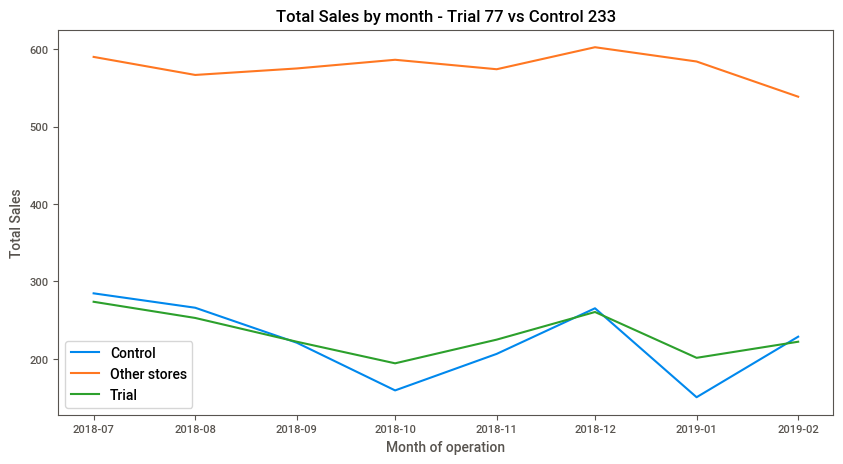

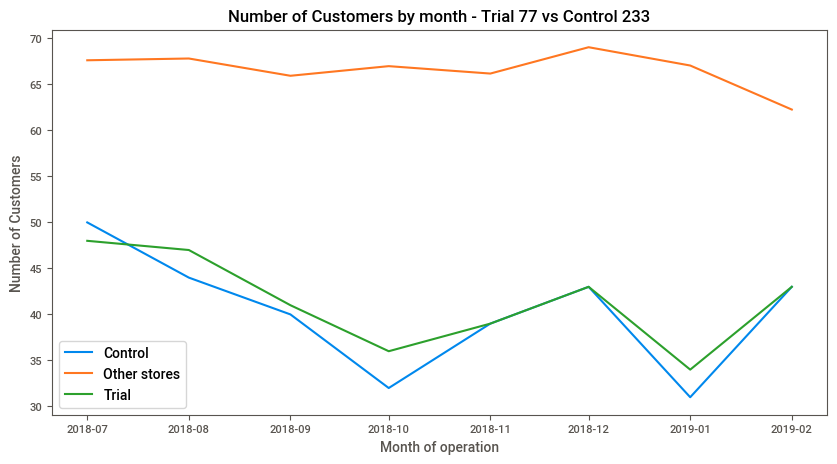

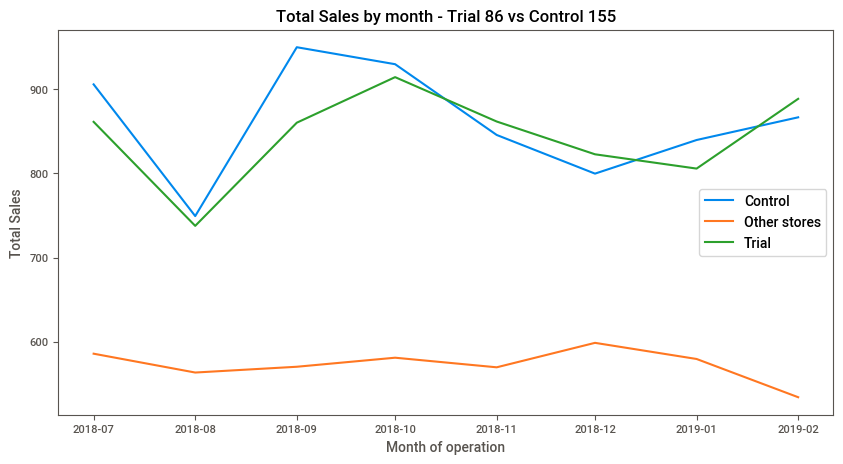

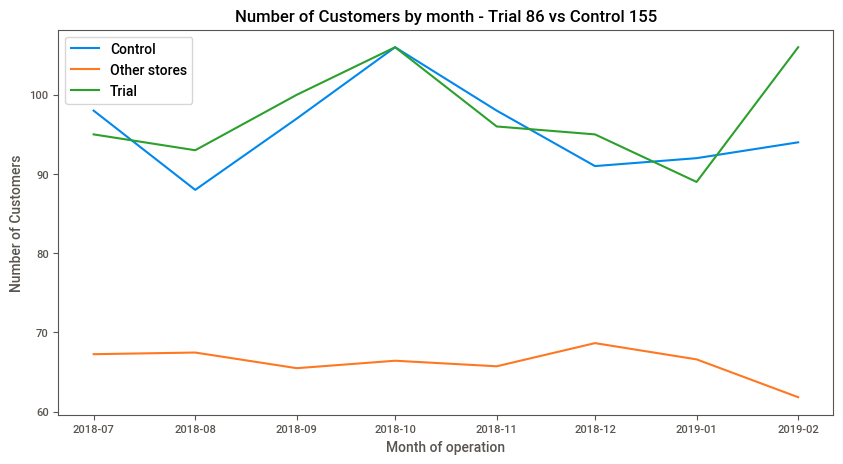

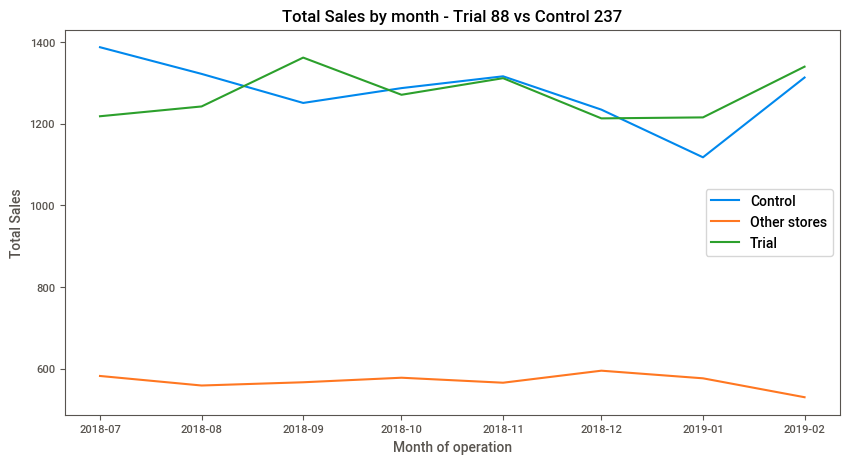

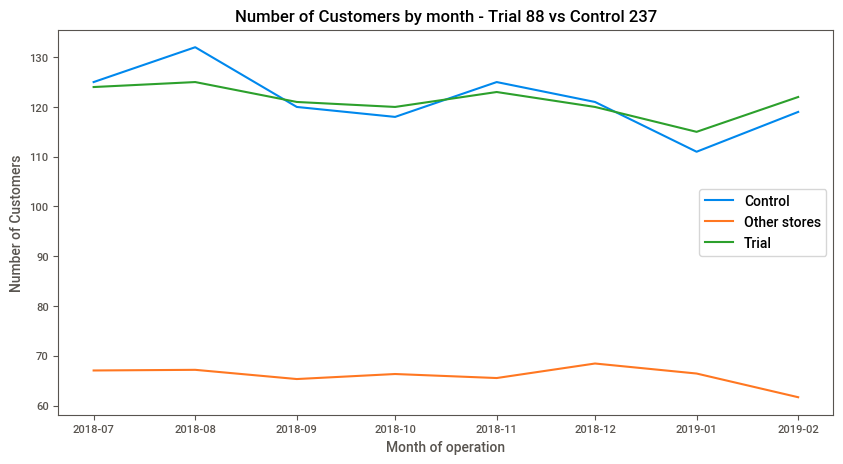

In [ ]:


def plot_pretrial_check(monthly_metrics, trial_store, control_store, metric, metric_label):
    df = monthly_metrics.copy()
    df["date"] = pd.to_datetime(df["yearmonth"].astype(str), format="%Y%m")

    df["Store_type"] = np.where(
        df["STORE_NBR"] == trial_store, "Trial",
        np.where(df["STORE_NBR"] == control_store, "Control", "Other stores")
    )

    grouped = df.groupby(["date", "Store_type"])[metric].mean().reset_index()
    grouped = grouped[grouped["date"] < pd.to_datetime("2019-03-01")]

    fig, ax = plt.subplots(figsize=(10, 5))
    for store_type, sub in grouped.groupby("Store_type"):
        sub = sub.sort_values("date")
        ax.plot(sub["date"], sub[metric], label=store_type)

    ax.set_title(f"{metric_label} by month - Trial {trial_store} vs Control {control_store}")
    ax.set_xlabel("Month of operation")
    ax.set_ylabel(metric_label)
    ax.legend()
    plt.show()


for store in stores:
    control = results[store]["control_store"]
    plot_pretrial_check(monthly_metrics, store, control, "total_sales", "Total Sales")
    plot_pretrial_check(monthly_metrics, store, control, "n_customers", "Number of Customers")

In [ ]:


def prepare_visualization_data(comparison_df, trial_store, std_df, std_col):
    plot_df = comparison_df.copy()
    std = std_df.loc[std_df["store"] == trial_store, std_col].iloc[0]

    plot_df["upper_band"] = plot_df["expected_trial"] * (1 + 2 * std)
    plot_df["lower_band"] = plot_df["expected_trial"] * (1 - 2 * std)

    return plot_df

In [ ]:


def plot_trial_assessment(plot_df, trial_store, metric_name):
    plot_data = plot_df.copy()

    plot_data["date"] = pd.to_datetime(
        plot_data["yearmonth"].astype(str),
        format="%Y%m"
    )

    trial_dates = plot_data.loc[plot_data["period"] == "Trial", "date"]
    trial_start = trial_dates.min()
    trial_end = trial_dates.max()

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.axvspan(trial_start, trial_end, color="gray", alpha=0.3, label="Trial Period")

    ax.plot(plot_data["date"], plot_data["upper_band"], linestyle="--", label="Upper Confidence Band")
    ax.plot(plot_data["date"], plot_data["lower_band"], linestyle="--", label="Lower Confidence Band")
    ax.plot(plot_data["date"], plot_data["expected_trial"], linewidth=2, label="Expected (Scaled Control)")
    ax.plot(plot_data["date"], plot_data["trial_actual"], linewidth=2, label=f"Trial Store {trial_store}")

    ax.set_title(f"{metric_name} - Trial Store {trial_store}")
    ax.set_xlabel("Month")
    ax.set_ylabel(metric_name)
    ax.legend()
    plt.show()

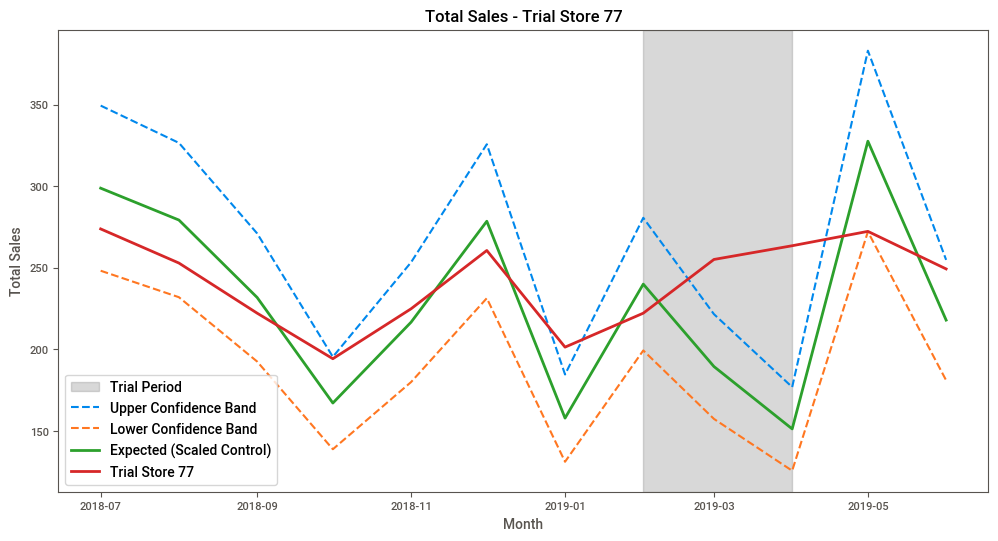

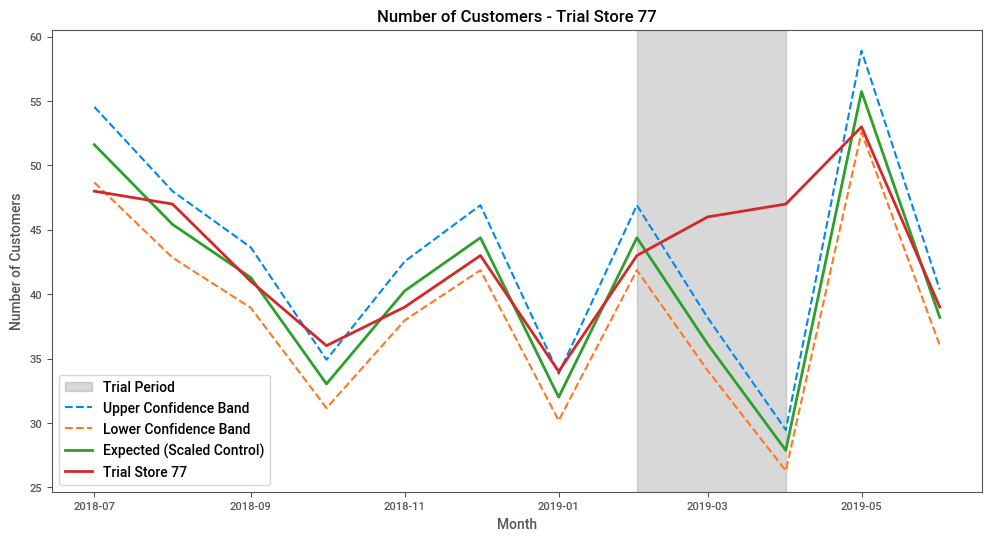

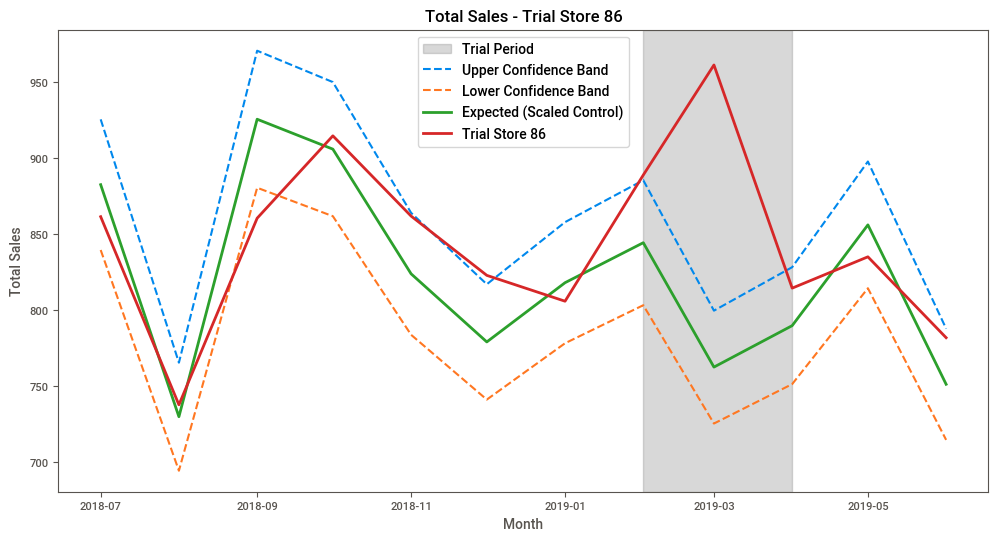

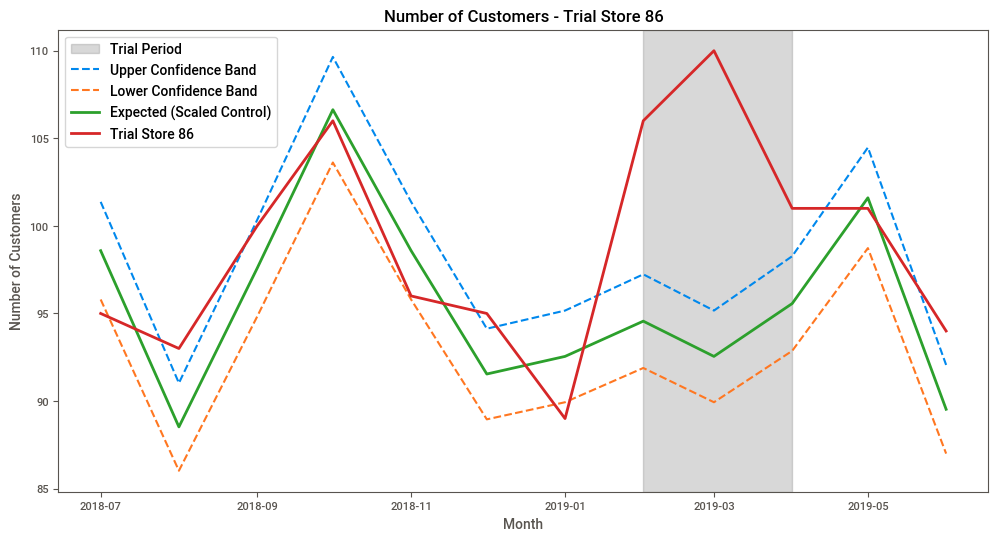

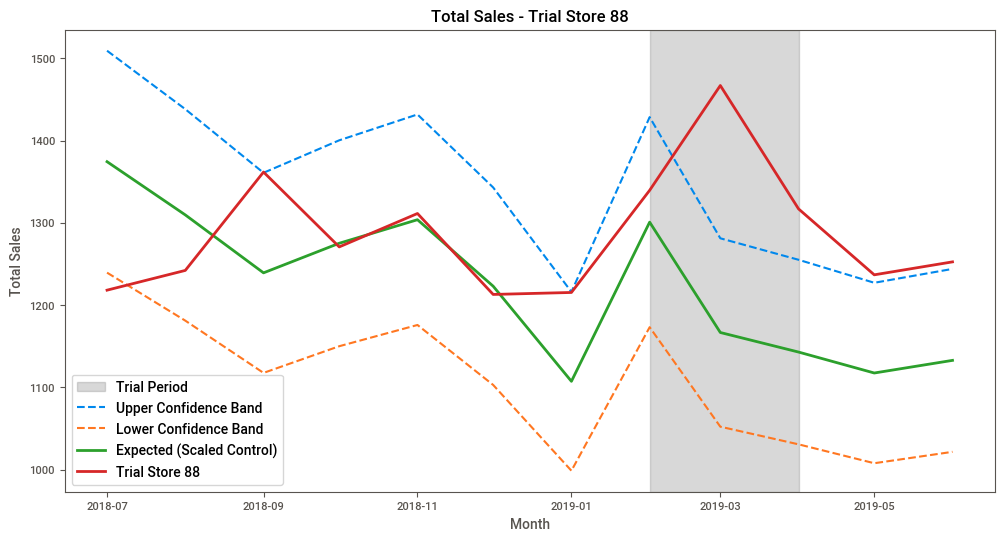

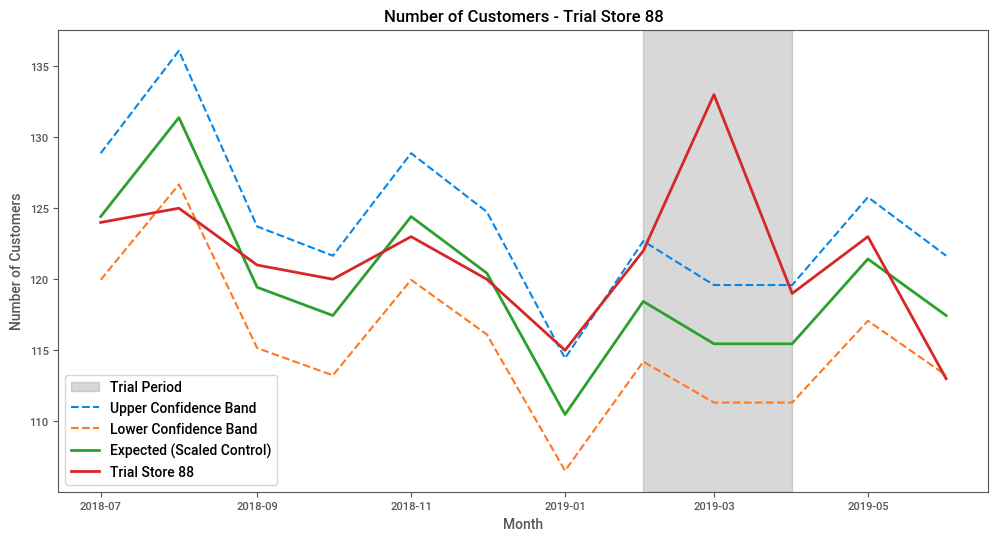

In [ ]:


metric_std_col = {"sales": "std_sales_pre", "customer": "std_customer_pre"}
metric_label = {"sales": "Total Sales", "customer": "Number of Customers"}

for store in stores:
    for metric in ["sales", "customer"]:
        plot_data = prepare_visualization_data(
            full_comparisons[store][f"{metric}_full"],
            trial_store=store,
            std_df=merged_std,
            std_col=metric_std_col[metric]
        )
        plot_trial_assessment(
            plot_data,
            trial_store=store,
            metric_name=metric_label[metric]
        )

In [ ]:


print("Conclusion")
print("=" * 60)
for store in stores:
    control = results[store]["control_store"]
    print(f"Trial store {store} -> Control store {control}")
    for metric in ["sales", "customer"]:
        trial_df = results[store][f"{metric}_trial"]
        sig_months = trial_df.loc[trial_df["t_value"] > t_critical, "yearmonth"].tolist()
        verdict = "significant uplift" if len(sig_months) >= 2 else "not significant"
        print(f"  {metric_label[metric]}: {verdict} (significant months: {sig_months if sig_months else 'none'})")
    print()

Conclusion
Trial store 77 -> Control store 233
  Total Sales: significant uplift (significant months: [201903, 201904])
  Number of Customers: significant uplift (significant months: [201903, 201904])

Trial store 86 -> Control store 155
  Total Sales: significant uplift (significant months: [201902, 201903])
  Number of Customers: significant uplift (significant months: [201902, 201903, 201904])

Trial store 88 -> Control store 237
  Total Sales: significant uplift (significant months: [201903, 201904])
  Number of Customers: not significant (significant months: [201903])

